In [1024]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy import stats
from scipy.signal import detrend, butter, filtfilt, welch
from scipy.fft import rfft, rfftfreq
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

from v2_data_preparation import slice_by_dates, handle_missing_values, load_and_prepare_data, process_insitu

#### Preprocesamiento SAR

Asmub et al 2019 aplican una normalizacion a los datos de retrodispersion para minimizar el efecto del angulo de incidencia sobre los datos. El metodo consiste en determinar la relacion lineal entre backscatter y angulo de incidencia y luego ajustar cada observación a un ángulo de referencia (mitad del rango observado == 38.5) utilizando dicha relacion.

In [1025]:
sar = pd.read_csv("../data/processed/satellites/SDH1_S1_2014-10_2026-09_Mono_Lee_12x12_dB.csv")

# 1. Asegurar tipo numérico y filtrar filas con NaN o infinitos en las columnas clave
sar['angle'] = pd.to_numeric(sar['angle'], errors='coerce')
sar['VV'] = pd.to_numeric(sar['VV'], errors='coerce')

# Máscara de datos válidos para el ajuste
valid_mask = sar['angle'].notna() & sar['VV'].notna() & np.isfinite(sar['angle']) & np.isfinite(sar['VV'])

# 2. Calcular la pendiente usando solo datos válidos
beta, intercept = np.polyfit(sar.loc[valid_mask, 'angle'], sar.loc[valid_mask, 'VV'], deg=1)
print(f"Pendiente constante (beta) estimada: {beta:.4f} dB/Grado")
print(f"Intercepto estimado: {intercept:.4f} dB")

# 3. Definir el ángulo de referencia
ref_angle = 38.5

# 4. Aplicar la ecuación de normalización (omite NaN)
col_name = f'VV_{ref_angle}_dB'
sar[col_name] = sar['VV'] - beta * (sar['angle'] - ref_angle)

# Visualizar el resultado omitiendo NaN
print(sar.dropna().tail())

Pendiente constante (beta) estimada: -0.2889 dB/Grado
Intercepto estimado: -3.8956 dB
      Timestamps       orbit      angle         VV         VH  VV_38.5_dB
1293  2026-08-26  DESCENDING  32.682583 -11.862978 -29.356236  -13.543546
1294  2026-09-02  DESCENDING  44.935013 -16.043410 -26.531136  -14.184427
1295  2026-09-07  DESCENDING  32.683960 -10.529031 -27.006074  -12.209201
1296  2026-09-13   ASCENDING  37.583370 -10.788711 -25.099877  -11.053512
1297  2026-09-14  DESCENDING  44.936119 -13.759456 -24.092750  -11.900154


In [1026]:
# Conversion a formato datetime
sar["Timestamps"] = pd.to_datetime(sar["Timestamps"], format="%Y-%m-%d")

# Establecimiento de datetime index y remocion de datos duplicados 
# (ej: orbitas ascendentes y descendentes coincidentes)
sar_cleaned = sar.drop_duplicates(
    subset=["Timestamps"], keep="first").set_index(
        "Timestamps").sort_index()

Resampleo semanal para contar con series continuas sin NaN

In [1027]:
# Convertir dB a escala lineal antes de resamplear. Usa la VV normalizada
# lineal = 10^(dB / 10)
sar_cleaned['VV_38.5_linear'] = 10 ** (sar_cleaned[col_name] / 10)

In [1028]:
# Reindexar a frecuencia semanal
sar_weekly = sar_cleaned[['VV_38.5_linear']].resample('W').mean()

In [1029]:
# Recorte a periodo donde NaN no ocurren dos semanas seguidas e interpolacion lineal de NaNs
sar_weekly_2017 = (
    slice_by_dates(sar_weekly, '2017-02', '2026-06')
    .pipe(handle_missing_values, method='time')
)

In [1030]:
# Volver a convertir el promedio semanal a dB
sar_weekly_2017[f'{col_name}'] = 10 * np.log10(sar_weekly_2017['VV_38.5_linear'])

# Eliminar columna auxiliar lineal
sar_weekly_2017 = sar_weekly_2017.drop(columns=['VV_38.5_linear'])

#### Preprocesamiento datos in situ

In [1031]:
# Procesamiento básico
insitu = process_insitu(
    filepath='../data/processed/in-situ/SDH1_daily-insitu-data.csv',
    start_date='2024-05-22',
    end_date='2026-05-14',
    cols_to_keep=['SDH1PS01_gw-depth_m', 
                  'ATMOS41_precipitation_mm', 
                  'TEROS12-05cm_soil-temperature_degreeC', 
                  'TEROS12-15cm_soil-temperature_degreeC',
                  'ATMOS41_air-temperature_degreeC'
                  ],
    outlier_threshold=3,
    ignore_outliers_cols=['ATMOS41_precipitation_mm']
)

# Resampleo a escala semanal
insitu_weekly_2024 = insitu.resample('W').agg({
    'SDH1PS01_gw-depth_m': 'mean',
    'ATMOS41_precipitation_mm': 'sum',
    'TEROS12-05cm_soil-temperature_degreeC': 'min', 
    'TEROS12-15cm_soil-temperature_degreeC': 'min',
    'ATMOS41_air-temperature_degreeC': 'min'
})

#### Union datos in situ y SAR

In [1032]:
weekly_df = insitu_weekly_2024.join(sar_weekly_2017, how='inner')
print('NaNs:')
weekly_df.isna().sum()

NaNs:


SDH1PS01_gw-depth_m                       0
ATMOS41_precipitation_mm                  0
TEROS12-05cm_soil-temperature_degreeC    44
TEROS12-15cm_soil-temperature_degreeC     0
ATMOS41_air-temperature_degreeC           9
VV_38.5_dB                                0
dtype: int64

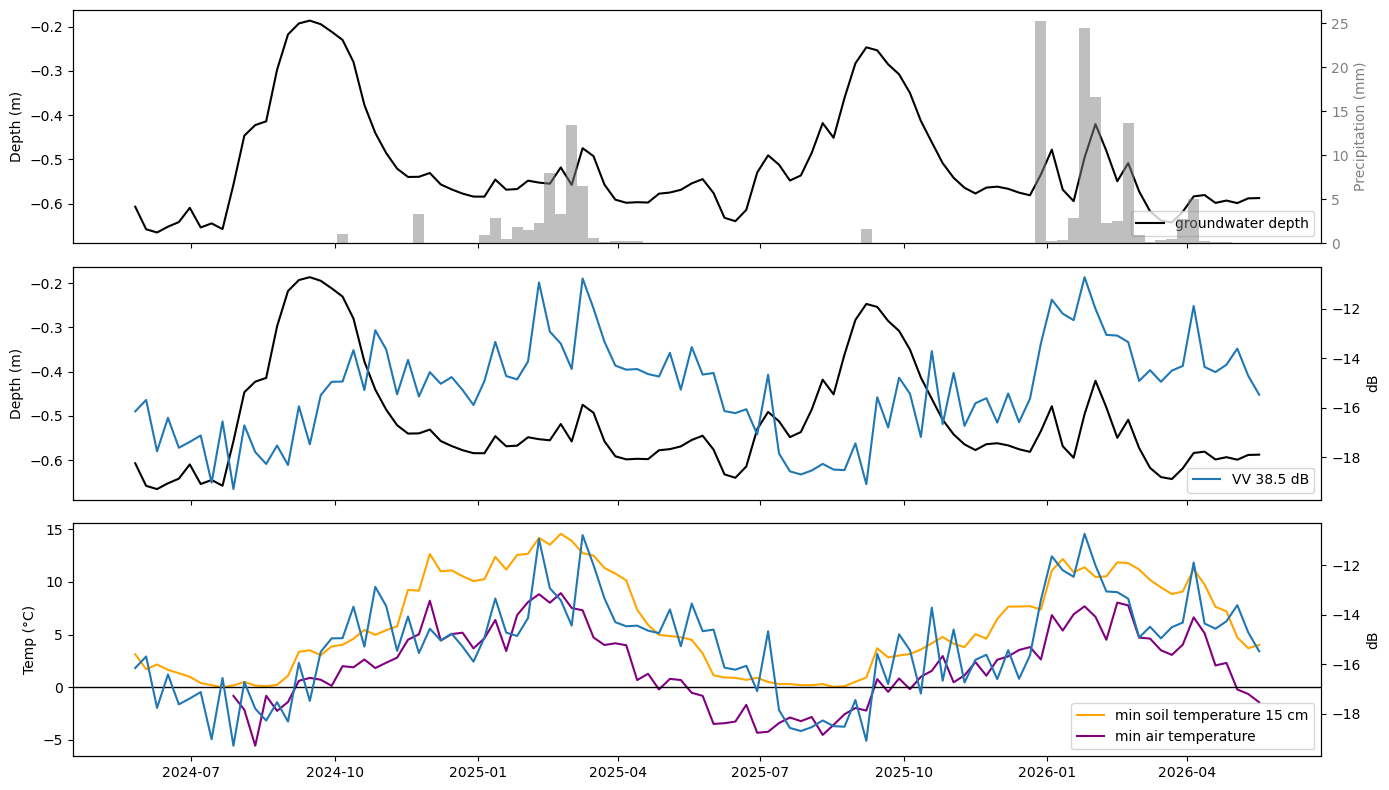

In [1033]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Plot superior
ax1.plot(weekly_df.index, weekly_df['SDH1PS01_gw-depth_m'], label='groundwater depth', c='black')
ax1.set_ylabel('Depth (m)')
ax1.legend(loc='lower right')

ax4 = ax1.twinx()
ax4.bar(weekly_df.index, weekly_df['ATMOS41_precipitation_mm'], width=7, color='gray', alpha=0.5, label='Precipitation (mm)')
ax4.set_ylabel('Precipitation (mm)', color='gray')
ax4.tick_params(axis='y', labelcolor='gray')

# Plot medio
ax2.plot(weekly_df.index, weekly_df['SDH1PS01_gw-depth_m'], label='groundwater depth', c='black')
ax2.set_ylabel('Depth (m)')

ax5 = ax2.twinx()
ax5.plot(weekly_df.index, weekly_df['VV_38.5_dB'], label = 'VV 38.5 dB')
ax5.legend(loc='lower right')
ax5.set_ylabel('dB')

# Plot inferior
#ax3.plot(weekly_df.index, weekly_df['TEROS12-05cm_soil-temperature_degreeC'], label='min soil temperature 5 cm', c='red')
ax3.plot(weekly_df.index, weekly_df['TEROS12-15cm_soil-temperature_degreeC'], label='min soil temperature 15 cm', c='orange')
ax3.plot(weekly_df.index, weekly_df['ATMOS41_air-temperature_degreeC'], label='min air temperature', c='purple')
ax3.set_ylabel('Temp (°C)')
ax3.legend(loc='lower right')
ax3.axhline(c='black', linewidth=1)

ax6 = ax3.twinx()
ax6.plot(weekly_df.index, weekly_df['VV_38.5_dB'], label = 'VV 38.5 dB')
ax6.set_ylabel('dB')

plt.tight_layout()
plt.show()

In [1034]:
weekly_df_diff = weekly_df.diff()

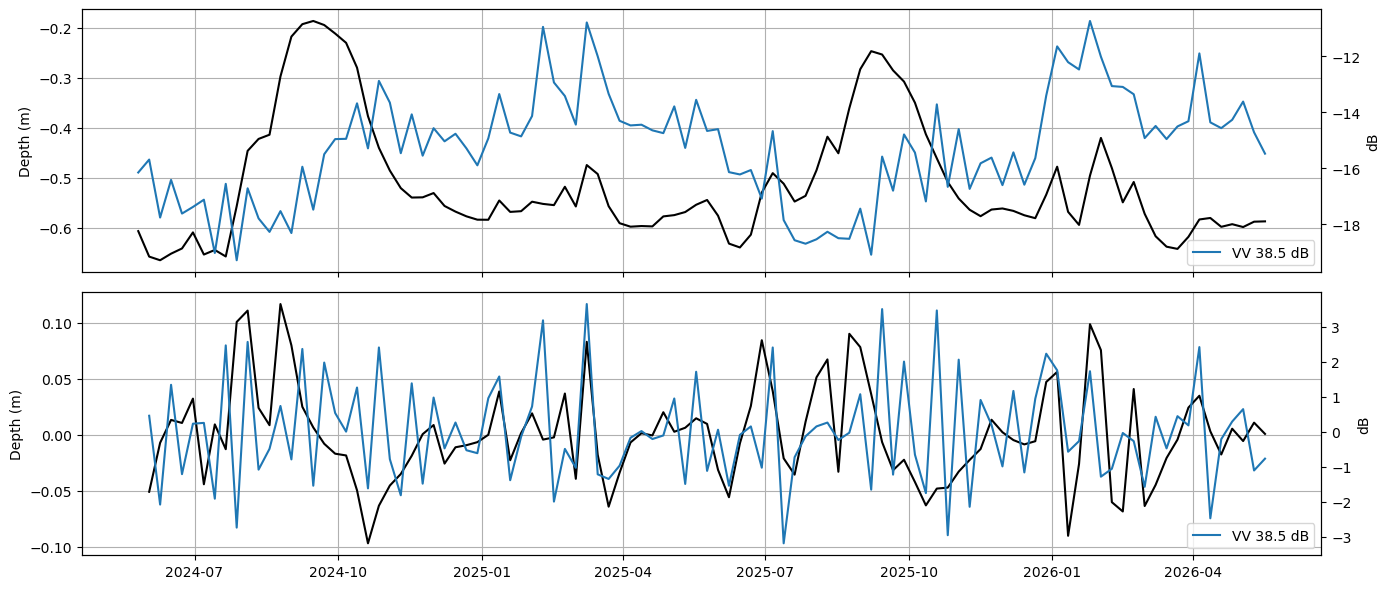

In [1035]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# Plot superior
ax1.plot(weekly_df.index, weekly_df['SDH1PS01_gw-depth_m'], label='groundwater depth', c='black')
ax1.set_ylabel('Depth (m)')
ax1.grid()

ax3 = ax1.twinx()
ax3.plot(weekly_df.index, weekly_df['VV_38.5_dB'], label = 'VV 38.5 dB')
ax3.legend(loc='lower right')
ax3.set_ylabel('dB')

# Plot inferior
ax2.plot(weekly_df_diff.index, weekly_df_diff['SDH1PS01_gw-depth_m'], label='groundwater depth', c='black')
ax2.set_ylabel('Depth (m)')
ax2.grid()

ax4 = ax2.twinx()
ax4.plot(weekly_df_diff.index, weekly_df_diff['VV_38.5_dB'], label = 'VV 38.5 dB')
ax4.legend(loc='lower right')
ax4.set_ylabel('dB')


plt.tight_layout()
plt.show()

#### Filtrado de series con Fourier

Cálculo del espectro de Fourier para identificar frecuencias

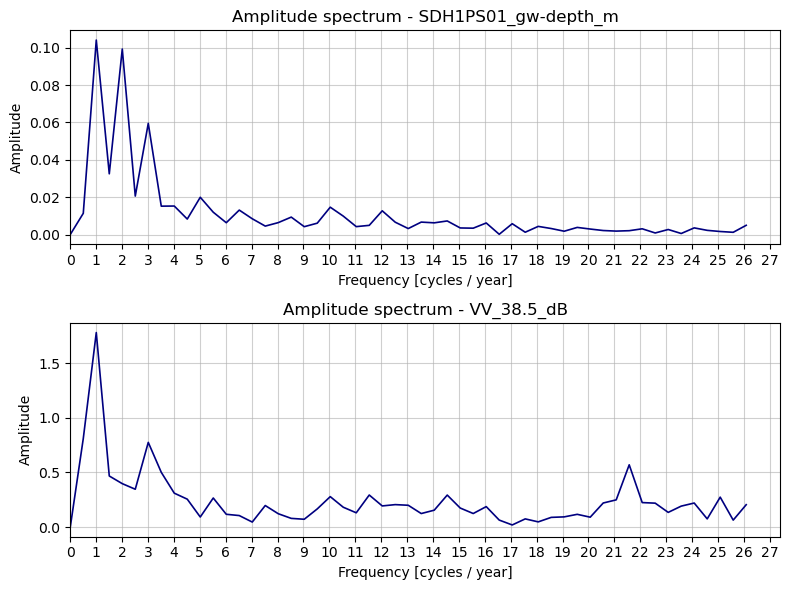

In [1036]:
def compute_fft_spectrum(series: pd.Series, sampling_interval_weeks: float = 1.0):
    """Computes the single-sided amplitude spectrum of a real-valued time series.

    Parameters:
        series (pd.Series): Time series data indexed by datetime.
        sampling_interval_weeks (float): Sampling step in weeks (default is 1.0).

    Returns:
        tuple[np.ndarray, np.ndarray]: Frequencies (cycles per year) and
        amplitudes.
    """
    # Remove missing values to ensure a continuous sequence
    clean_series = series.dropna()

    # Detrend the series to eliminate the zero-frequency (DC) offset
    # type=constant: substracts the mean, type=linear: a linear least-squares fit to data is subtracted
    detrended_values = detrend(clean_series.values, type='linear')
    sample_count = len(detrended_values)

    # Compute positive frequencies in cycles per week
    frequencies_per_week = rfftfreq(sample_count, d=sampling_interval_weeks)

    # Convert frequencies to cycles per year for easier hydrological interpretation
    frequencies_per_year = frequencies_per_week * 52.1775

    # Compute the Fourier transform and normalize amplitude
    fft_coefficients = rfft(detrended_values)
    amplitude_spectrum = (2.0 / sample_count) * np.abs(fft_coefficients)

    return frequencies_per_year, amplitude_spectrum


def plot_fourier_spectra(spectra_dict: dict):
    """Plots amplitude spectra for multiple time series signals side by side."""
    figure, axes = plt.subplots(
        nrows=len(spectra_dict), ncols=1, figsize=(8, 3 * len(spectra_dict))
    )

    # Handle single subplot case cleanly
    if len(spectra_dict) == 1:
        axes = [axes]

    for axis, (signal_name, (frequencies, amplitudes)) in zip(
        axes, spectra_dict.items()
    ):
        axis.plot(frequencies, amplitudes, color="navy", lw=1.2)
        axis.set_title(f"Amplitude spectrum - {signal_name}", fontsize=12)
        axis.set_xlabel("Frequency [cycles / year]", fontsize=10)
        axis.set_ylabel("Amplitude", fontsize=10)
        axis.grid(True, linestyle="-", alpha=0.6)
        axis.set_xlim(left=0)
        axis.xaxis.set_major_locator(MultipleLocator(1.0))

    plt.tight_layout()
    plt.show()


# --- Execution workflow ---

# Define the target columns from your dataframe
target_columns = ["SDH1PS01_gw-depth_m", "VV_38.5_dB"]

# Calculate spectra for both signals
computed_spectra = {}
for column_name in target_columns:
    frequencies, amplitudes = compute_fft_spectrum(weekly_df[column_name])
    computed_spectra[column_name] = (frequencies, amplitudes)

# Visualize the resulting frequency spectra
plot_fourier_spectra(computed_spectra)

Nivel freatico: 
- frec 1 -> pulso de primavera
- frec 2 -> pulsos de primavera y verano
- frec 3 -> pulsos de primavera y verano (temprano) + rebote de invierno

Backscatter:
- frec 1 -> pulso de verano
- frec 2 -> pulsos de primavera (temprano) y de verano (tardío) NO ES MUY REPRESENTATIVO FISICAMENTE
- frec 3 -> pulsos de primavera y de verano + rebote de invierno

Aplicación de filtros de Fourier

In [1037]:
def apply_lowpass_filter(
    series: pd.Series,
    cutoff_cycles_per_year: float = 1.0,
    sampling_rate_per_year: float = 52.1775,
    filter_order: int = 1,
) -> pd.Series:
    """Computes coefficients and applies a zero-phase Butterworth low-pass filter.

    Parameters:
        series (pd.Series): Input time series indexed by datetime.
        cutoff_cycles_per_year (float): Upper frequency threshold in cycles/year.
        sampling_rate_per_year (float): Total samples per year (52.1775 for weekly data).
        filter_order (int): Order of the Butterworth filter.

    Returns:
        pd.Series: Low-pass filtered signal preserving the original datetime index.
    """
    clean_series = series.dropna()

    # Calculate Nyquist frequency and normalized cutoff
    nyquist_frequency = 0.5 * sampling_rate_per_year
    normalized_cutoff = cutoff_cycles_per_year / nyquist_frequency

    # Compute filter coefficients
    b_coefficients, a_coefficients = butter(
        N=filter_order, Wn=normalized_cutoff, btype="low", analog=False
    )

    # Perform zero-phase filtering (forward and backward passes)
    filtered_values = filtfilt(b_coefficients, a_coefficients, clean_series.values)

    return pd.Series(
        data=filtered_values, index=clean_series.index, name=f"{series.name}_lowpass"
    )


def apply_bandpass_filter(
    series: pd.Series,
    low_cutoff_cycles_per_year: float = 0.8,
    high_cutoff_cycles_per_year: float = 1.2,
    sampling_rate_per_year: float = 52.1775,
    filter_order: int = 1,
) -> pd.Series:
    """Computes coefficients and applies a zero-phase Butterworth bandpass filter.

    Parameters:
        series (pd.Series): Input time series indexed by datetime.
        low_cutoff_cycles_per_year (float): Lower frequency boundary in cycles/year.
        high_cutoff_cycles_per_year (float): Upper frequency boundary in cycles/year.
        sampling_rate_per_year (float): Total samples per year (52.1775 for weekly data).
        filter_order (int): Order of the Butterworth filter.

    Returns:
        pd.Series: Bandpass filtered signal preserving the original datetime index.
    """
    clean_series = series.dropna()

    # Calculate Nyquist frequency and normalized cutoff boundaries
    nyquist_frequency = 0.5 * sampling_rate_per_year
    normalized_low_cutoff = low_cutoff_cycles_per_year / nyquist_frequency
    normalized_high_cutoff = high_cutoff_cycles_per_year / nyquist_frequency
    band_cutoffs = [normalized_low_cutoff, normalized_high_cutoff]

    # Compute bandpass filter coefficients
    b_coefficients, a_coefficients = butter(
        N=filter_order, Wn=band_cutoffs, btype="bandpass", analog=False
    )

    # Perform zero-phase filtering
    filtered_values = filtfilt(b_coefficients, a_coefficients, clean_series.values)

    return pd.Series(
        data=filtered_values, index=clean_series.index, name=f"{series.name}_bandpass"
    )


def plot_lowpass_comparison(original_series: pd.Series, filtered_series: pd.Series):
    """Plots original signal overlaid with the low-pass filtered signal."""
    plt.figure(figsize=(8, 3))
    plt.plot(
        original_series.index,
        original_series.values,
        label="Original signal",
        color="gray",
        alpha=0.5,
        lw=1.0,
    )
    plt.plot(
        filtered_series.index,
        filtered_series.values,
        label="Filtered signal",
        color="crimson",
        lw=1.5,
    )
    plt.title(f"Low-pass filtering - {original_series.name}", fontsize=12)
    plt.xlabel("Date", fontsize=10)
    plt.ylabel(original_series.name, fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


def plot_bandpass_comparison(
    original_series: pd.Series,
    filtered_series: pd.Series,
    overlay_with_mean: bool = True,
):
    """Plots original time series alongside its bandpass-filtered counterpart.

    Parameters:
        original_series (pd.Series): Raw input time series indexed by datetime.
        filtered_series (pd.Series): Bandpass filtered time series.
        overlay_with_mean (bool): If True, restores the mean of the original signal
            to the filtered series on the overlay plot for direct visual comparison.
    """
    clean_original = original_series.dropna()
    clean_filtered = filtered_series.dropna()

    figure, axes = plt.subplots(
        nrows=2, ncols=1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]}
    )

    # Top panel: direct overlay
    axes[0].plot(
        clean_original.index,
        clean_original.values,
        label="Original signal",
        color="slategray",
        alpha=0.6,
        lw=1.0,
    )

    if overlay_with_mean:
        series_mean = clean_original.mean()
        reconstructed_signal = clean_filtered.values + series_mean
        curve_label = "Bandpass component (centered on mean)"
    else:
        reconstructed_signal = clean_filtered.values
        curve_label = "Bandpass component"

    axes[0].plot(
        clean_filtered.index,
        reconstructed_signal,
        label=curve_label,
        color="crimson",
        lw=1.8,
    )
    axes[0].set_title(f"Bandpass filter comparison - {original_series.name}", fontsize=12)
    axes[0].set_ylabel(original_series.name, fontsize=10)
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend(loc="upper right")

    # Bottom panel: isolated zero-centered seasonal oscillation
    axes[1].plot(
        clean_filtered.index,
        clean_filtered.values,
        label="Isolated seasonal oscillation",
        color="navy",
        lw=1.4,
    )
    axes[1].axhline(0, color="black", linestyle=":", alpha=0.7)
    axes[1].set_ylabel("Amplitude deviation", fontsize=10)
    axes[1].set_xlabel("Date", fontsize=10)
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()

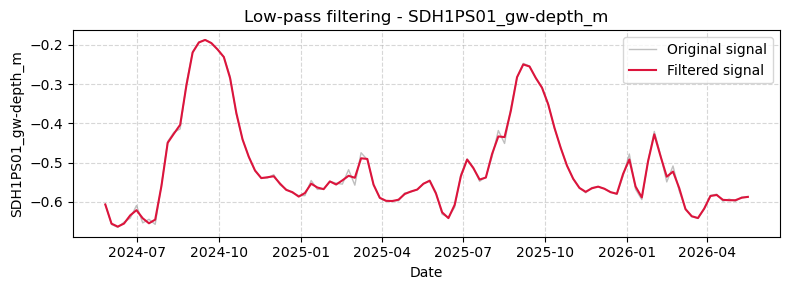

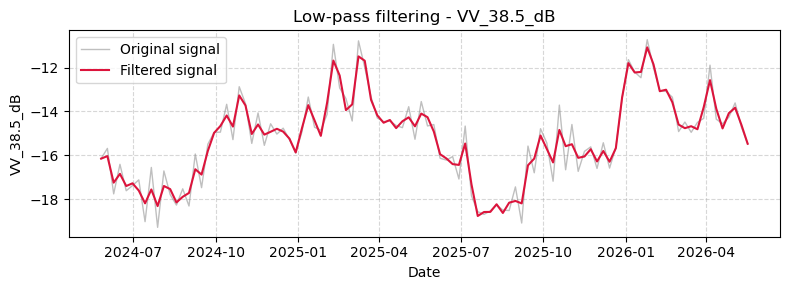

In [1038]:
# --- Execution workflow ---

target_columns = ["SDH1PS01_gw-depth_m", "VV_38.5_dB"]
lowpass_results = {}
bandpass_results = {}

for column_name in target_columns:
    # 1. Low-pass filter
    lowpass_series = apply_lowpass_filter(
        weekly_df[column_name],
        cutoff_cycles_per_year=20
    )
    lowpass_results[column_name] = lowpass_series
    plot_lowpass_comparison(weekly_df[column_name], lowpass_series)

    # 2. Bandpass filter
    bandpass_series = apply_bandpass_filter(
        weekly_df[column_name],
        low_cutoff_cycles_per_year=2.5,
        high_cutoff_cycles_per_year=20,
    )
    bandpass_results[column_name] = bandpass_series
    #plot_bandpass_comparison(weekly_df[column_name], bandpass_series)

Quitar frecuencias bajas me sirve para eliminar la autocorrelación de la serie.
Quitar frecuencias altas me sirve para elimianr el efecto de eventos puntuales.

#### Filtrado con SARIMAX

In [1039]:
# Definicion de variables
x = weekly_df['SDH1PS01_gw-depth_m']
y = weekly_df['VV_38.5_dB']
z = weekly_df['ATMOS41_precipitation_mm']
w = weekly_df['TEROS12-15cm_soil-temperature_degreeC']

##### Transformacion de series

In [1040]:
# Funciones para transformar series
def detrend_series(series_x, series_y, type='linear'):

    x_detrended = pd.Series(
        detrend(series_x, type=type), 
        index=series_x.index, 
        name=series_x.name
    )
    y_detrended = pd.Series(
        detrend(series_y, type=type), 
        index=series_y.index, 
        name=series_y.name
    )

    return x_detrended, y_detrended

def normalize_series(series_x, series_y):
    # De-mean and normalize to unit standard deviation
    x_normalized = (series_x - np.mean(series_x)) / np.std(series_x, ddof=0)
    y_normalized = (series_y - np.mean(series_y)) / np.std(series_y, ddof=0)

    return x_normalized, y_normalized

<Axes: >

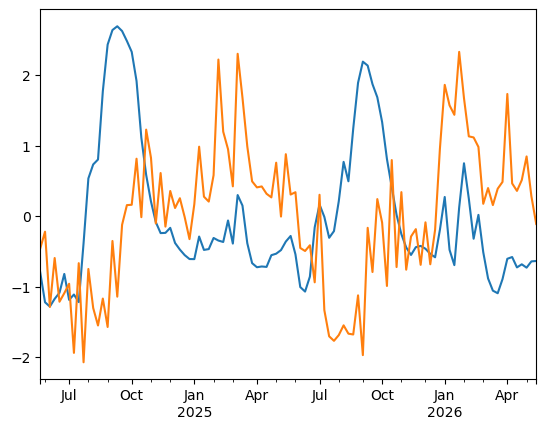

In [1041]:
# Ploteo de series sin transformaciones (solo normalizacion para visualizacion)
x_norm, y_norm = normalize_series(x, y)
x_norm.plot()
y_norm.plot()

In [1042]:
# Detrend de series
# type = constant: resta la media, type = linear: resta un ajuste por mínimos cuadrados
x_detrend, y_detrend = detrend_series(
    series_x=x, 
    series_y=y,
    type='linear'
)
z_detrend, _ = detrend_series(
    series_x=z, 
    series_y=y,
    type='linear'
)

In [1043]:
# Estandarizacion de series
x_detr_norm, y_detr_norm = normalize_series(
    x_detrend, 
    y_detrend
)
z_detr_norm, _ = normalize_series(
    z_detrend, 
    y_detrend
)
# x_detr_norm.plot()
# y_detr_norm.plot()

##### Evaluacion de las frecuencias dentro de las series

In [1044]:
# Funciones para calcular y plotear la PSD
def compute_power_spectral_density(time_series, sample_rate_per_year=52.0, max_lags=60):

    series_array = np.asarray(time_series, dtype=float)
    num_samples = len(series_array)
    centered_series = series_array - np.mean(series_array)

    # Compute power spectral density using Welch's method
    frequencies, power_spectrum = welch(
        centered_series, 
        fs=sample_rate_per_year, 
        nperseg=num_samples
    )

    return {
        'frequencies': frequencies,
        'power_spectrum': power_spectrum
    }

def plot_psd(results_x, results_y, label_x="x", label_y="y"):

    fig, axes = plt.subplots(2, 1, figsize=(10, 5))
    
    # Spectrum series X
    axes[0].plot(results_x['frequencies'], results_x['power_spectrum'], color='tab:blue')
    axes[0].set_title(f"power spectrum: {label_x}")
    axes[0].set_xlabel("frequency (cycles/year)")
    axes[0].set_ylabel("density")
    axes[0].set_xlim(left=0)
    axes[0].xaxis.set_major_locator(MultipleLocator(1.0))
    
    # Spectrum series Y
    axes[1].plot(results_y['frequencies'], results_y['power_spectrum'], color='tab:green')
    axes[1].set_title(f"power spectrum: {label_y}")
    axes[1].set_xlabel("frequency (cycles/year)")
    axes[1].set_ylabel("density")
    axes[1].set_xlim(left=0)
    axes[1].xaxis.set_major_locator(MultipleLocator(1.0))


    plt.tight_layout()
    plt.show()

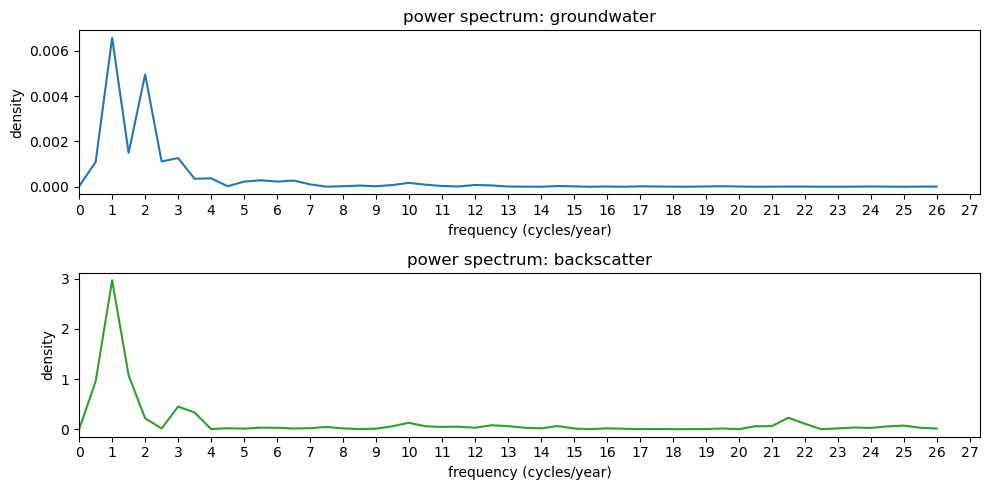

In [1045]:
# Evaluacion de la densidad espectral de potencia
psd_gwl = compute_power_spectral_density(x)
psd_sar = compute_power_spectral_density(y)
plot_psd(psd_gwl, psd_sar, 'groundwater', 'backscatter')

La serie backscatter tiene un ciclo en 21.5 que podria ser atribuible al angulo de vision del satelite, lo que podria removerse con un filtro de paso bajo en la frecuencia 20-21

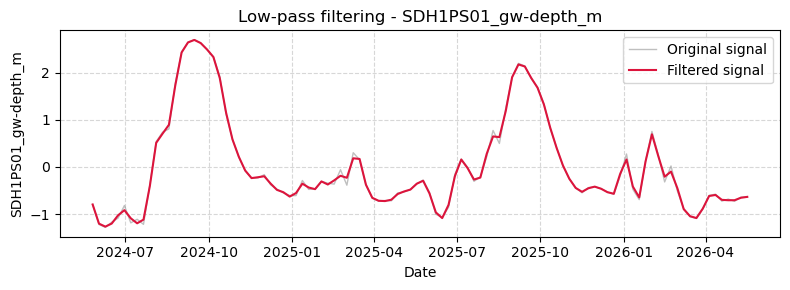

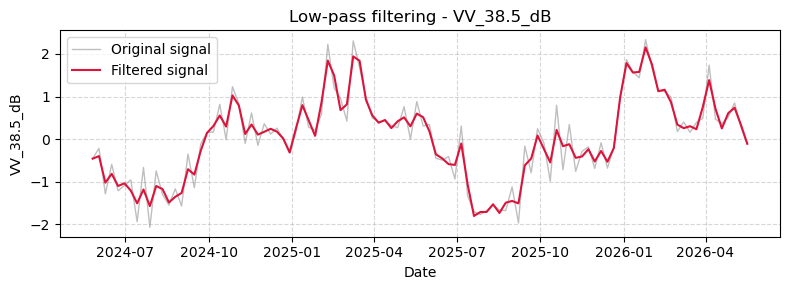

In [1046]:
# Evaluacion del filtro de paso bajo para remover los cambios de angulo de vision en sar
joined_normal = pd.concat([x_norm, y_norm], axis=1)
target_columns = ["SDH1PS01_gw-depth_m", "VV_38.5_dB"]
lowpass_results = {}

for column_name in target_columns:
    lowpass_series = apply_lowpass_filter(
        joined_normal[column_name],
        cutoff_cycles_per_year=20
    )
    lowpass_results[column_name] = lowpass_series
    plot_lowpass_comparison(joined_normal[column_name], lowpass_series)

In [1047]:
lowpass_results

{'SDH1PS01_gw-depth_m': 2024-05-26   -0.794513
 2024-06-02   -1.200747
 2024-06-09   -1.263756
 2024-06-16   -1.198705
 2024-06-23   -1.024087
                 ...   
 2026-04-19   -0.696145
 2026-04-26   -0.704264
 2026-05-03   -0.704074
 2026-05-10   -0.651930
 2026-05-17   -0.633117
 Name: SDH1PS01_gw-depth_m_lowpass, Length: 104, dtype: float64,
 'VV_38.5_dB': 2024-05-26   -0.456955
 2024-06-02   -0.397519
 2024-06-09   -1.020440
 2024-06-16   -0.813927
 2024-06-23   -1.099422
                 ...   
 2026-04-19    0.252221
 2026-04-26    0.609471
 2026-05-03    0.737968
 2026-05-10    0.337698
 2026-05-17   -0.107670
 Name: VV_38.5_dB_lowpass, Length: 104, dtype: float64}

##### Evaluacion de estacionariedad

In [1048]:
# Funciones para evaluar estacionariedad
# Codes adapted from https://www.statsmodels.org/stable/examples/notebooks/generated/stationarity_detrending_adf_kpss.html#Detrending-by-Differencing

def adf_test(series, alpha_value=0.05):
    """
    Calcula la prueba de Dickey-Fuller aumentada para evaluar la estacionariedad de la serie.
    H0 = la serie es no estacionaria (tiene una raiz unitaria); H1 = la serie es estacionaria.
    """
    # Calcula el test
    adf_test = adfuller(series)
    
    # Almacena los resultados del test en una serie
    adf_output = pd.Series(
        adf_test[0:4],
        index=[
            "Test statistic",
            "p-value",
            "Lags used",
            "Observations used"
            ])
    
    # Itera sobre el output #5 (valores criticos) para almacenarlos
    for key, value in adf_test[4].items():
        adf_output["Critical Value (%s)" % key] = value

    # Imprime los resultados del test
    print("--- Augmented Dickey-Fuller Test ---")
    print(adf_output)

    # Evalua e imprime los resultados del test de hipotesis
    if adf_output['p-value'] <= alpha_value:
        print(f"\nEl p-value ({adf_output['p-value']:.4f}) es menor o igual que {alpha_value}.")
        print('Se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.\n')
    else:
        print(f"\nEl p-value ({adf_output['p-value']:.4f}) es mayor que {alpha_value}.")
        print('No se rechaza la hipótesis nula (H0). La serie temporal es NO estacionaria.\n')


def kpss_test(series, alpha_value=0.05):
    """
    Calcula la prueba de Kwiatkowski-Phillips-Schmidt-Shin para evaluar la estacionariedad de la serie.
    H0 = la serie es estacionaria; H1 = la serie es NO estacionaria (tiene una raiz unitaria)
    """
    # Calcula el test
    kpsstest = kpss(series)

    # Almacena los resultados del test en una serie
    kpss_output = pd.Series(
        kpsstest[0:3], 
        index=["Test statistic", 
               "p-value", 
               "Lags used"])

    # Itera sobre el output #4 (valores criticos) para almacenarlos
    for key, value in kpsstest[3].items():
        kpss_output["Critical Value (%s)" % key] = value
    
    # Imprime los resultados del test
    print("--- KPSS Test ---")
    print(kpss_output)

    # Evalua e imprime los resultados del test de hipotesis
    if kpss_output['p-value'] <= alpha_value:
        print(f"\nEl p-value ({kpss_output['p-value']:.4f}) es menor o igual que {alpha_value}.")
        print('Se rechaza la hipótesis nula (H0). La serie temporal es no estacionaria.\n')
    else:
        print(f"\nEl p-value ({kpss_output['p-value']:.4f}) es mayor que {alpha_value}.")
        print('No se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.\n')

In [1049]:
# Evaluacion de estacionariedad de las series originales
print('RESULTADOS GWL')
adf_test(x)
kpss_test(x)
print('RESULTADOS SAR')
adf_test(y)
kpss_test(y)
print('RESULTADOS PP')
adf_test(z)
kpss_test(z)

RESULTADOS GWL
--- Augmented Dickey-Fuller Test ---
Test statistic          -3.769057
p-value                  0.003240
Lags used                4.000000
Observations used       99.000000
Critical Value (1%)     -3.498198
Critical Value (5%)     -2.891208
Critical Value (10%)    -2.582596
dtype: float64

El p-value (0.0032) es menor o igual que 0.05.
Se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

--- KPSS Test ---
Test statistic           0.11902
p-value                  0.10000
Lags used                5.00000
Critical Value (10%)     0.34700
Critical Value (5%)      0.46300
Critical Value (2.5%)    0.57400
Critical Value (1%)      0.73900
dtype: float64

El p-value (0.1000) es mayor que 0.05.
No se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

RESULTADOS SAR
--- Augmented Dickey-Fuller Test ---
Test statistic          -1.991719
p-value                  0.290216
Lags used                9.000000
Observations used       94.000000
Critical V

Según los test, la serie de nivel freático es estacionaria, mientras que la serie de backscatter lo es según ADF, pero no lo es según KPSS. De acuerdo con el tutorial del link anterior:

Case 4: KPSS indicates non-stationarity and ADF indicates stationarity - The series is difference stationary. Differencing is to be used to make series stationary. 

Para las precipitaciones es al revés: según ADF es no estacionaria y según KPSS sí por lo que:

Case 3: KPSS indicates stationarity and ADF indicates non-stationarity - The series is trend stationary. Trend needs to be removed to make series strict stationary.

No obstante, más abajo se prueba a detrendear eliminando la tendencia linear y no cambia el resultado.

In [1050]:
# Diferenciacion para hacer series Y y Z estacionarias
x_diff = x.diff().dropna()
y_diff = y.diff().dropna()
z_diff = z.diff().dropna()

In [1051]:
# Evaluacion de estacionariedad de las series diferenciadas
print('RESULTADOS GWL')
adf_test(x_diff)
kpss_test(x_diff)
print('RESULTADOS SAR DIFERENCIADOS')
adf_test(y_diff)
kpss_test(y_diff)
print('RESULTADOS PP DIFERENCIADOS')
adf_test(z_diff)
kpss_test(z_diff)

RESULTADOS GWL
--- Augmented Dickey-Fuller Test ---
Test statistic           -4.470523
p-value                   0.000222
Lags used                 2.000000
Observations used       100.000000
Critical Value (1%)      -3.497501
Critical Value (5%)      -2.890906
Critical Value (10%)     -2.582435
dtype: float64

El p-value (0.0002) es menor o igual que 0.05.
Se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

--- KPSS Test ---
Test statistic           0.073041
p-value                  0.100000
Lags used                3.000000
Critical Value (10%)     0.347000
Critical Value (5%)      0.463000
Critical Value (2.5%)    0.574000
Critical Value (1%)      0.739000
dtype: float64

El p-value (0.1000) es mayor que 0.05.
No se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

RESULTADOS SAR DIFERENCIADOS
--- Augmented Dickey-Fuller Test ---
Test statistic          -5.021816
p-value                  0.000020
Lags used                8.000000
Observations use

Al diferenciar una vez, backscatter y precipitaciones se estacionarizan para ambos test.

In [1052]:
# Evaluacion de estacionariedad de las series detrend
print('RESULTADOS GWL')
adf_test(x_detrend)
kpss_test(x_detrend)
print('RESULTADOS SAR')
adf_test(y_detrend)
kpss_test(y_detrend)
print('RESULTADOS PP')
adf_test(z_detrend)
kpss_test(z_detrend)

RESULTADOS GWL
--- Augmented Dickey-Fuller Test ---
Test statistic          -3.962093
p-value                  0.001623
Lags used                4.000000
Observations used       99.000000
Critical Value (1%)     -3.498198
Critical Value (5%)     -2.891208
Critical Value (10%)    -2.582596
dtype: float64

El p-value (0.0016) es menor o igual que 0.05.
Se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

--- KPSS Test ---
Test statistic           0.072
p-value                  0.100
Lags used                5.000
Critical Value (10%)     0.347
Critical Value (5%)      0.463
Critical Value (2.5%)    0.574
Critical Value (1%)      0.739
dtype: float64

El p-value (0.1000) es mayor que 0.05.
No se rechaza la hipótesis nula (H0). La serie temporal es estacionaria.

RESULTADOS SAR
--- Augmented Dickey-Fuller Test ---
Test statistic          -1.806243
p-value                  0.377367
Lags used                9.000000
Observations used       94.000000
Critical Value (1%)     

El metodo detrend con type constant o linear no logran estacionarizar las series de backscatter ni de precipitación para efectos del test ADF (la diferenciación sí).

##### Evaluacion de autocorrelacion de las series

                 GWL                  |            SAR                 |              PP


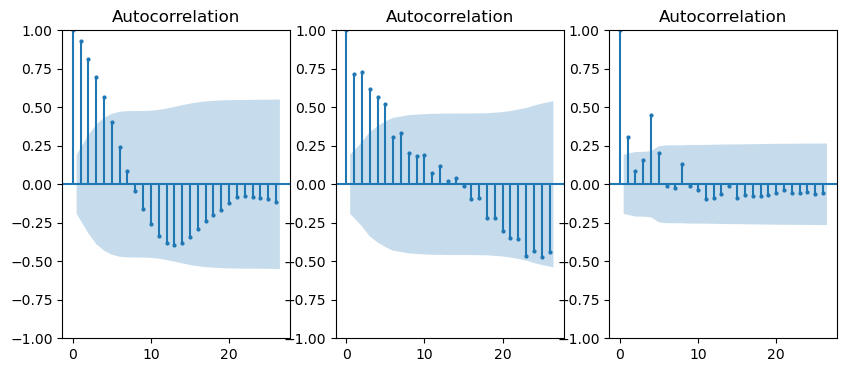

In [1053]:
# Evaluacion de autocorrelacion de series originales
print('                 GWL                  |            SAR                 |              PP')
fig, axes = plt.subplots(1, 3, figsize=(10,4))
plot_acf(x, ax=axes[0], lags=26, markersize=2)
plot_acf(y, ax=axes[1], lags=26, markersize=2)
plot_acf(z, ax=axes[2], lags=26, markersize=2)
plt.show()


               GWL DETREND            |          SAR DETREND          |           PP DETREND


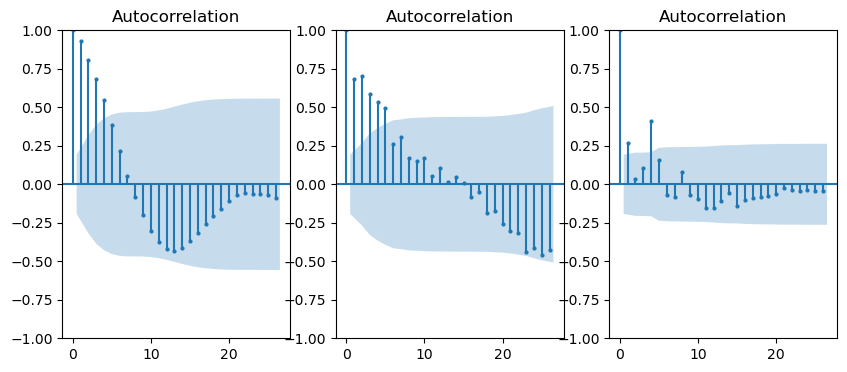

In [1054]:
# Evaluacion de autocorrelacion de series detrendeadas
print('               GWL DETREND            |          SAR DETREND          |           PP DETREND')
fig, axes = plt.subplots(1, 3, figsize=(10,4))
plot_acf(x_detrend, ax=axes[0], lags=26, markersize=2)
plot_acf(y_detrend, ax=axes[1], lags=26, markersize=2)
plot_acf(z_detrend, ax=axes[2], lags=26, markersize=2)
plt.show()

               GWL DIFF              |          SAR DIFF             |           PP DIFF


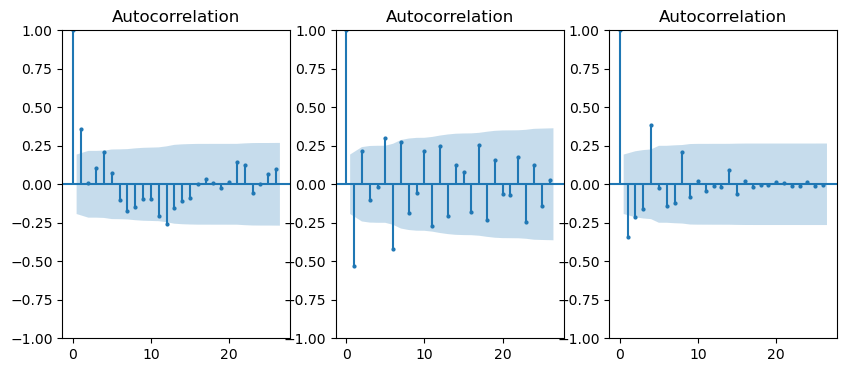

In [1055]:
# Evaluacion de autocorrelacion de series diferenciadas
print('               GWL DIFF              |          SAR DIFF             |           PP DIFF')
fig, axes = plt.subplots(1, 3, figsize=(10,4))
plot_acf(x_diff, ax=axes[0], lags=26, markersize=2)
plot_acf(y_diff, ax=axes[1], lags=26, markersize=2)
plot_acf(z_diff, ax=axes[2], lags=26, markersize=2)
plt.show()

La diferenciación tiene un mejor desempeño eliminando la autocorrelación y asegurando la estacionariedad que el detrend mediante regresión linear (y por media)

RESUMEN DIAGNOSICO:

x es estacionaria según ADF y KPSS y autocorrelacionada viendo el acf plot
Y es estacionaria según ADF y no estacionaria según KPSS y autocorrelacionada viendo el acf plot
Z es no estacionaria según ADF y estacionaria según KPSS y autocorrelacionada viendo el acf plot

Al aplicar detrending restando la tendencia lineal de las series, los resultados anteriores no cambian.

Al aplicar diferenciación de primer orden, todas las series son estacionarias según ADF y KPSS y están menos autocorrelacionadas viendo el acf plot.

##### Remocion del efecto exogeno con SARIMAX

In [1060]:
def remove_exogenous_effect(target_series, exogenous_series, lags_exog=1, order=(1,0,1)):
    """
    Ajusta un modelo ARIMAX para estimar el impacto de una variable exógena
    y la sustrae de la serie original sin romper la continuidad temporal.
    """

    # 1. Construir la matriz de regresores exógenos (efecto contemporáneo + retardos)
    df_exog = pd.DataFrame({'lag_0': exogenous_series})
    for l in range(1, lags_exog + 1):
        df_exog[f'lag_{l}'] = exogenous_series.shift(l)

    # Rellenar los primeros retardos con el primer valor para evitar pérdida de filas
    df_exog = df_exog.bfill()

    # 2. Ajustar el modelo ARIMAX
    model = SARIMAX(
        endog=target_series,
        exog=df_exog,
        order=order,
        trend='c',
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    # 3. Extraer coeficientes asociados a la variable exógena
    names_exog = df_exog.columns
    coefs_exog = model.params[names_exog].values

    # 4. Calcular el efecto marginal total de Z sobre la serie en cada semana: Z_t * beta
    effect_exog = np.dot(df_exog.values, coefs_exog)
    effect_series = pd.Series(effect_exog, index=target_series.index)

    # 5. Sustraer el efecto para obtener la serie depurada (contrafactual)
    clean_series = target_series - effect_series
    clean_series.name = f"{target_series.name}_clean"

    return clean_series, effect_series

In [1061]:
# Funcion para automatizar la deteccion de valores optimos para ARIMAX

import itertools
import warnings

def optimizar_arimax(endog, exog, max_p=3, max_q=3, max_lags_exog=4):
    """
    Evalúa combinaciones de (p, q) y rezagos exógenos,
    retornando la combinación con el menor AIC.
    """
    warnings.filterwarnings("ignore")
    
    mejor_aic = np.inf
    mejores_params = None
    
    # Evaluar distintos números de rezagos para la variable Z
    for l in range(0, max_lags_exog + 1):
        df_exog = pd.DataFrame({'lag_0': exog})
        for lag in range(1, l + 1):
            df_exog[f'lag_{lag}'] = exog.shift(lag)
        df_exog = df_exog.bfill()
        
        # Grid search sobre p y q (manteniendo d=0)
        for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
            if p == 0 and q == 0 and l == 0:
                continue
            try:
                mod = SARIMAX(
                    endog=endog,
                    exog=df_exog,
                    order=(p, 0, q),
                    trend='c',
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit(disp=False)
                
                if mod.aic < mejor_aic:
                    mejor_aic = mod.aic
                    mejores_params = {'order': (p, 0, q), 'lags_exog': l, 'aic': mod.aic}
            except Exception:
                continue
                
    return mejores_params

# params_x = optimizar_arimax(x, z)
# params_y = optimizar_arimax(y, z)
# print("Mejores parámetros para X:", params_x)
# print("Mejores parámetros para Y:", params_y)

In [1062]:
# Eliminacion de efecto de la pp con ARIMAX
x_clean, effect_series_x = remove_exogenous_effect(x, z, lags_exog=2, order=(2,0,0))
y_clean, effect_series_y = remove_exogenous_effect(y, z, lags_exog=3, order=(3,0,2))

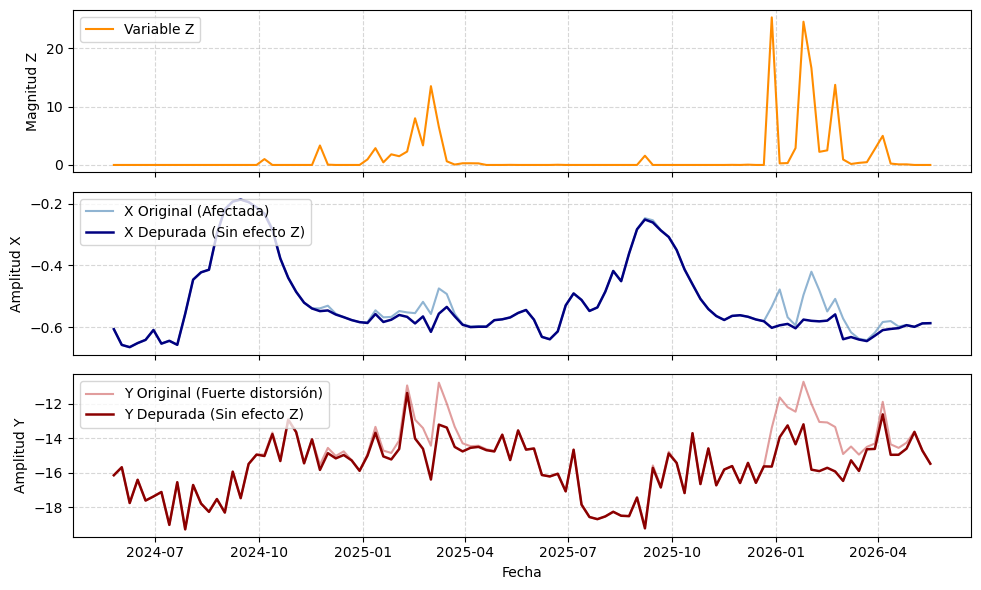

In [1063]:
# Visualizacion de remocion de efecto de la pp
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

# Panel 1: Variable exógena Z
axes[0].plot(z.index, z, color="darkorange", label="Variable Z")
axes[0].set_ylabel("Magnitud Z")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Comparativa Serie X
axes[1].plot(x.index, x, label="X Original (Afectada)", color="steelblue", alpha=0.6)
axes[1].plot(x_clean.index, x_clean, label="X Depurada (Sin efecto Z)", color="navy", linewidth=1.8)
axes[1].set_ylabel("Amplitud X")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Comparativa Serie Y
axes[2].plot(y.index, y, label="Y Original (Fuerte distorsión)", color="indianred", alpha=0.6)
axes[2].plot(y_clean.index, y_clean, label="Y Depurada (Sin efecto Z)", color="darkred", linewidth=1.8)
axes[2].set_ylabel("Amplitud Y")
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.xlabel("Fecha")
plt.tight_layout()
plt.show()

Pareciera que el efecto de la precipitación sobre las series objetivos es proporcional al agua caída. Esto es adecuado para el nivel freático, pero no para el backscatter, que se dispara ante la mínima precipitación.

##### Remocion del efecto exogeno con SARIMAX y un umbral

In [1064]:
def remove_exogenous_effect_threshold(
        target_series,
        exogenous_series,
        exog_thresh=None,
        thresh_eval='gte',        # gte, lte
        lags_exog=1, 
        order=(1,0,1)):
    """
    Ajusta un modelo ARIMAX para estimar el impacto de una variable exógena
    y la sustrae de la serie original sin romper la continuidad temporal.
    """
    # 0. Transformar variable exogena segun umbral
    if exog_thresh is not None:
        if thresh_eval == 'gte':
            exog_transf = (exogenous_series >= exog_thresh).astype(float)
        elif thresh_eval == 'lte':
            exog_transf = (exogenous_series <= exog_thresh).astype(float)
        else:
            raise ValueError(f"thresh_eval no reconocido: {thresh_eval}. Usa 'gte' o 'lte'.")
    else:
        exog_transf = exogenous_series
        
    # 1. Construir la matriz de regresores exógenos (efecto contemporáneo + retardos)
    df_exog = pd.DataFrame({'lag_0': exog_transf})
    for l in range(1, lags_exog + 1):
        df_exog[f'lag_{l}'] = exog_transf.shift(l)

    # Rellenar los primeros retardos con el primer valor para evitar pérdida de filas
    df_exog = df_exog.bfill()

    # 2. Ajustar el modelo ARIMAX
    model = SARIMAX(
        endog=target_series,
        exog=df_exog,
        order=order,
        trend='c',
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    # 3. Extraer coeficientes asociados a la variable exógena
    names_exog = df_exog.columns
    coefs_exog = model.params[names_exog].values

    # 4. Calcular el efecto marginal total de Z sobre la serie en cada semana: Z_t * beta
    effect_exog = np.dot(df_exog.values, coefs_exog)
    effect_series = pd.Series(effect_exog, index=target_series.index)

    # 5. Sustraer el efecto para obtener la serie depurada (contrafactual)
    clean_series = target_series - effect_series
    clean_series.name = f"{target_series.name}_clean"

    return clean_series, effect_series

In [ ]:
# Remocion de efectos de variables exogenas
# exog_thresh es el valor umbral de la variable exogena sobre el cual o bajo el cual se considera que genera efectos
# en pp son los mm para tener efecto sobre el backscatter o el nivel, en soil temp son los grados (a -15 cm) a los que ocurre congelamiento
# use un valor de 1 en soil temp considerando que en superficie hay menor temperatura que en profundidad.

# Para remover el efecto de la pp, se usa gte (greater than or equal)
x_clean_th_pp, effect_series_x_th_pp = remove_exogenous_effect_threshold(x, z, exog_thresh=3, thresh_eval='gte', lags_exog=1, order=(1,0,1))
y_clean_th_pp, effect_series_y_th_pp = remove_exogenous_effect_threshold(y, z, exog_thresh=1, thresh_eval='gte', lags_exog=3, order=(1,0,1))

# Para remover el efecto de la temperatura del suelo se usa lte (lesser than or equal)
x_clean_th_st, effect_series_x_th_st = remove_exogenous_effect_threshold(x, w, exog_thresh=1, thresh_eval='lte', lags_exog=1, order=(1,0,1))
y_clean_th_st, effect_series_y_th_st = remove_exogenous_effect_threshold(y, w, exog_thresh=1, thresh_eval='lte', lags_exog=3, order=(1,0,1))

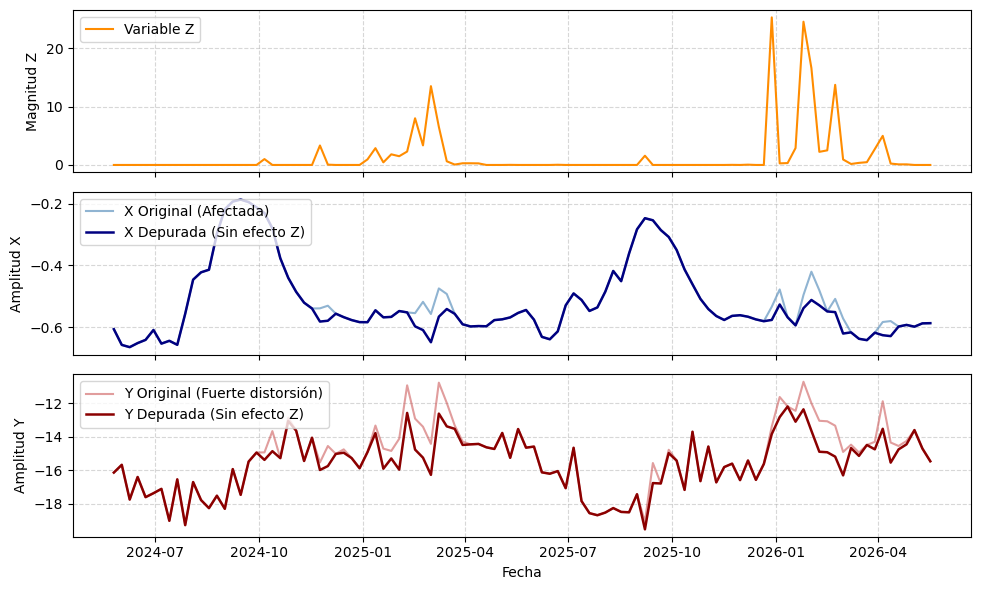

In [1066]:
# Visualizacion de remocion de efecto de la pp

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

# Panel 1: Variable exógena Z
axes[0].plot(z.index, z, color="darkorange", label="Variable Z")
axes[0].set_ylabel("Magnitud Z")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Comparativa Serie X
axes[1].plot(x.index, x, label="X Original (Afectada)", color="steelblue", alpha=0.6)
axes[1].plot(x_clean_th_pp.index, x_clean_th_pp, label="X Depurada (Sin efecto Z)", color="navy", linewidth=1.8)
axes[1].set_ylabel("Amplitud X")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Comparativa Serie Y
axes[2].plot(y.index, y, label="Y Original (Fuerte distorsión)", color="indianred", alpha=0.6)
axes[2].plot(y_clean_th_pp.index, y_clean_th_pp, label="Y Depurada (Sin efecto Z)", color="darkred", linewidth=1.8)
axes[2].set_ylabel("Amplitud Y")
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.xlabel("Fecha")
plt.tight_layout()
plt.show()

Este modelo de umbral no funciona muy bien para el nivel freático, funciona mejor la versión proporcional anterior. En el caso del backscatter se ven mejoras respecto a la versión anterior, pero de todas maneras no logra eleiminar todo el efecto de la precipitación, particularmente en 2026.

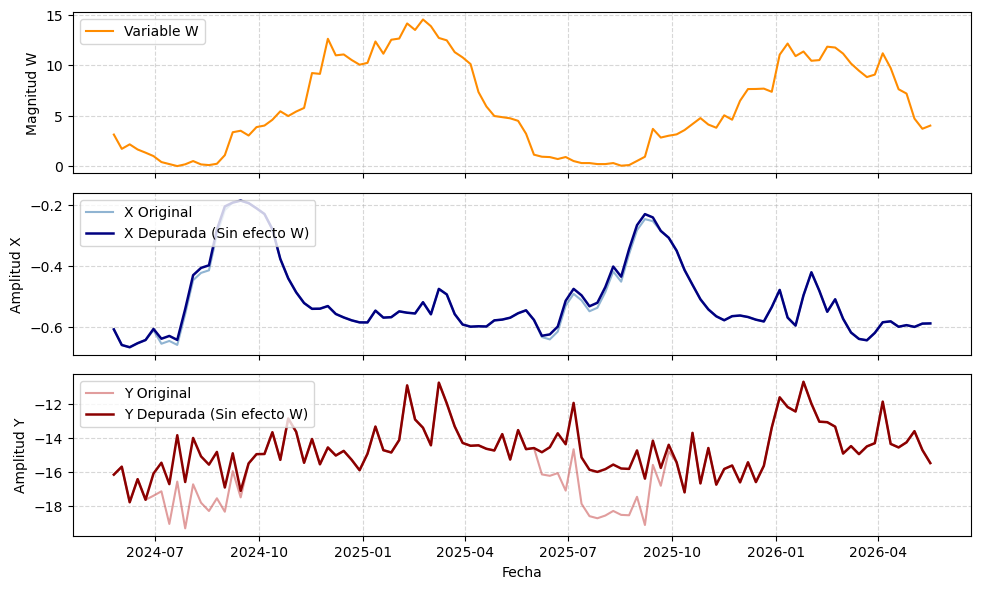

In [1067]:
# Visualizacion de remocion de efecto de la soil temperature
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

# Panel 1: Variable exógena W
axes[0].plot(w.index, w, color="darkorange", label="Variable W")
axes[0].set_ylabel("Magnitud W")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Comparativa Serie X
axes[1].plot(x.index, x, label="X Original", color="steelblue", alpha=0.6)
axes[1].plot(x_clean_th_st.index, x_clean_th_st, label="X Depurada (Sin efecto W)", color="navy", linewidth=1.8)
axes[1].set_ylabel("Amplitud X")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Comparativa Serie Y
axes[2].plot(y.index, y, label="Y Original", color="indianred", alpha=0.6)
axes[2].plot(y_clean_th_st.index, y_clean_th_st, label="Y Depurada (Sin efecto W)", color="darkred", linewidth=1.8)
axes[2].set_ylabel("Amplitud Y")
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.xlabel("Fecha")
plt.tight_layout()
plt.show()

Al aislar el efecto del suelo congelado, desaparece el pulso de primavera del backscatter.